# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
# ITBI Recife (Prefeitura do Recife, dados abertos, 2015-2023)
import zipfile
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
CAMINHO_ZIP = RAIZ / "data" / "raw" / "archive.zip"
PASTA_DADOS = RAIZ / "data" / "raw" / "itbi_data"

if not PASTA_DADOS.exists():
    with zipfile.ZipFile(CAMINHO_ZIP) as z:
        z.extractall(PASTA_DADOS)

arquivos = sorted(PASTA_DADOS.glob("itbi_*.csv"))
df = pd.concat(
    [pd.read_csv(a, sep=";", decimal=",", encoding="utf-8") for a in arquivos],
    ignore_index=True,
)
df["valor_avaliacao"] = df["valor_avaliacao"].astype(float)
df["data_transacao"] = pd.to_datetime(df["data_transacao"])
df.head()

## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o Heart Disease tem 13 variáveis preditoras (idade, sexo, tipo de dor no peito, pressão em repouso, colesterol, entre outras) mais o alvo (`num`, presença/grau de doença cardíaca). Quantas linhas vocês esperam que um dataset clínico como esse tenha — dezenas, centenas ou milhares de pacientes?

*Resposta*: 108.804 linhas — bem mais do que a maioria chutaria à primeira vista (9 anos de guias de ITBI de uma capital, então a ordem de grandeza certa é "dezenas de milhares por ano", não "centenas").

### Dimensão e Tipos de Dados

In [8]:
df.shape

(108804, 19)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 108804 entries, 0 to 108803
Data columns (total 19 columns):
 #   Column              Non-Null Count   Dtype         
---  ------              --------------   -----         
 0   logradouro          108804 non-null  object        
 1   numero              108804 non-null  int64         
 2   complemento         99656 non-null   object        
 3   bairro              108804 non-null  object        
 4   cidade              108804 non-null  object        
 5   uf                  108804 non-null  object        
 6   ano_construcao      108804 non-null  int64         
 7   area_terreno        108804 non-null  float64       
 8   area_construida     108804 non-null  float64       
 9   fracao_ideal        108804 non-null  float64       
 10  padrao_acabamento   108804 non-null  object        
 11  tipo_construcao     108804 non-null  object        
 12  tipo_ocupa          108804 non-null  object        
 13  valor_avaliacao     108804 no

In [10]:
df.describe()

,numero,ano_construcao,area_terreno,area_construida,fracao_ideal,valor_avaliacao,data_transacao,ano
count,108804.000000,108804.000000,108804.000000,108804.000000,108804.000000,1.088040e+05,108804,108804.000000
mean,605.319069,2002.169249,9780.994247,163.761901,0.109895,5.761425e+05,2019-09-14 03:48:53.090088704,2019.189809
min,-1.000000,1908.000000,0.000000,1.000000,0.000000,0.000000e+00,2015-01-02 08:18:03,2015.000000
25%,126.000000,1993.000000,962.000000,77.200000,0.005950,2.289264e+05,2017-05-31 10:03:18,2017.000000
50%,276.000000,2009.000000,1710.920000,102.060000,0.013515,3.500000e+05,2019-10-14 11:06:16,2019.000000
75%,635.000000,2016.000000,3518.730000,160.910000,0.029770,5.400000e+05,2022-01-03 23:21:52,2022.000000
max,9500.000000,2023.000000,299081.000000,72574.330000,3.285710,2.790000e+08,2023-12-30 10:00:20,2023.000000
std,945.530531,18.437419,33938.927989,682.135778,0.279791,2.245560e+06,NaN,2.599529


### Duplicadas

In [11]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [12]:
df["tipo_ocupa_bin"] = np.where(df["tipo_ocupa"] == "RESIDENCIAL", "Residencial", "Comercial")
df["tipo_ocupa_bin"].value_counts()
df.head()

,logradouro,numero,complemento,bairro,cidade,uf,ano_construcao,area_terreno,area_construida,fracao_ideal,padrao_acabamento,tipo_construcao,tipo_ocupa,valor_avaliacao,data_transacao,estado_conservacao,tipo_imovel,sfh,ano,tipo_ocupa_bin
0,RUA FRANCISCO DA CUNHA,1640,APTO 1302 BLOCO A,BOA VIAGEM,RECIFE,PE,2013,2760.96,173.18,0.00962,Superior,Apartamento > 4 Pavimentos,RESIDENCIAL,750000.0,2015-06-17 10:34:04,Bom,Apartamento,0.0,2015,Residencial
1,RUA LARGA DO FEITOSA,282,APTO 804 EDF MORADA LARGA DO FEITOSA,ENCRUZILHADA,RECIFE,PE,2015,1625.90,96.90,0.00985,Superior,Apartamento > 4 Pavimentos,RESIDENCIAL,295000.0,2015-09-14 10:20:13,Bom,Apartamento,188482.97,2015,Residencial
2,AV REPUBLICA DO LIBANO,251,SALA 2506 TORRE A,PINA,RECIFE,PE,2012,202710.70,115.04,0.00018,Superior,Sala > 4 Pavimentos,COMERCIAL COM LIXO ORGANICO,290000.0,2015-08-26 13:20:23,Bom,Sala,0.0,2015,Comercial
3,AV REPUBLICA DO LIBANO,251,SALA 2506 TORRE A,PINA,RECIFE,PE,2012,202710.70,115.04,0.00018,Superior,Sala > 4 Pavimentos,COMERCIAL COM LIXO ORGANICO,290000.0,2015-08-12 09:40:59,Bom,Sala,0.0,2015,Comercial
4,RUA JOSE MOREIRA LEAL,34,APTO 0202 EDF GOLDEN STAR,BOA VIAGEM,RECIFE,PE,2000,882.00,114.83,0.02247,Médio,Apartamento > 4 Pavimentos,RESIDENCIAL,290000.0,2015-06-04 12:29:41,Bom,Apartamento,0.0,2015,Residencial


## 2. Dados Faltantes

In [13]:
df.isna().sum()

,0
logradouro,0
numero,0
complemento,9148
bairro,0
cidade,0
uf,0
ano_construcao,0
area_terreno,0
area_construida,0
fracao_ideal,0


**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim. Duas colunas têm valores ausentes: `complemento` (~9.148 linhas, ~8,4%) e `sfh` (156 linhas, ~0,14%). Nenhuma das variáveis quantitativas centrais da análise (`ano_construcao`, `area_terreno`, `area_construida`, `fracao_ideal`, `valor_avaliacao`) tem ausentes — o que já muda o foco da Seção 4 em relação à demonstração: aqui não vai ser necessário remover linhas por ausência nas variáveis de interesse.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos dois features 'ca'e 'thal'com dados ausentes.

Pela fonte de dados observamos que:

* ca - número de vasos principais coloridos por fluroscopia
* thal - resultados do teste de estresse (talassemia)

*Como os dados foram coletados:*
- O conjunto de dados disponibilizado do UCI é um subconjunto de dados de experimentos publicados em 4 outros conjuntos médicos. Dos 4 conjuntos base para a construção deste dataset, apenas um deles foi utilizado por pesquisadores de Machine Learning anteriormente.

*Qual a natureza da fonte de dados:*
- Considerando que os dados são de pacientes médicos, sabemos que há desafios inerentes a lidar com pessoas nos estudos que podem não ter todos os resultados necessariamente.
- Além disso, o dataset condensa diferentes estudos (Cleveland, Hungary, Switzerland, and the VA Long Beach) de países diferentes, e alguns resultados, como os de *ca* e *thal*, podem ter sido faltantes devido a custos.

**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [14]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['complemento', 'sfh']
complemento    9148
sfh             156
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

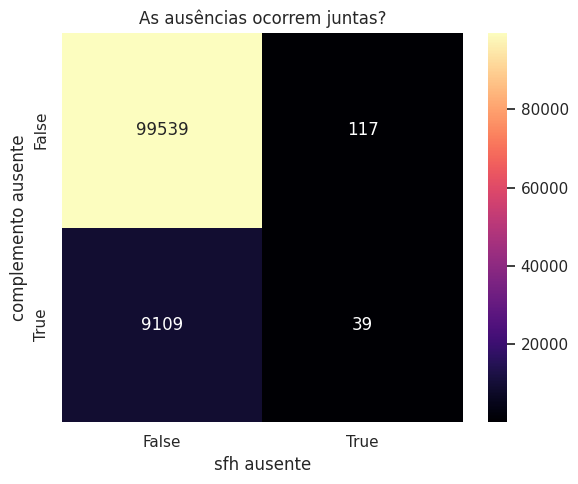

In [15]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

*Resposta*: 39 linhas têm `complemento` e `sfh` ausentes ao mesmo tempo (de 108.804). Isso é mais do que o esperado se as duas ausências fossem totalmente independentes (≈13 linhas, calculando 9.148 × 156 / 108.804), mas ainda um volume baixo em termos absolutos. Não é evidência forte de um mecanismo único de ausência afetando as duas colunas juntas — é mais consistente com dois problemas de cadastro distintos (endereço sem complemento por não se aplicar; campo de financiamento não preenchido) do que com um único evento (ex: um mesmo formulário mal preenchido).

- *Se supormos que a ausência depende do próprio valor que está faltando*: por exemplo, o paciente não fez o exame porque já se suspeitava (por sinais clínicos observados previamente) que o resultado seria anormal, e o exame extra não seria necessário, isso seria classificado como **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si*: por exemplo, o protocolo de coleta decidiu não solicitar aquele exame, ou o custo do procedimento limitou a coleta, independente do que o resultado provavelmente seria — isso seria classificado como **MAR** (ou até **MCAR**, se a decisão for arbitrária e não sistemática).

Não dá pra decidir entre as duas só olhando os dados — é exatamente o tipo de situação em que testes estatísticos (como o teste de MCAR) e conhecimento de domínio real (falar com quem coletou os dados) resolveriam a dúvida. Na ausência disso, seguimos com a opção mais conservadora na hora de tratar.

**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [16]:
VARS_QUANT = ["ano_construcao", "area_terreno", "area_construida", "fracao_ideal", "valor_avaliacao"]
VARS_QUALI = ["padrao_acabamento", "estado_conservacao", "tipo_imovel", "tipo_construcao", "tipo_ocupa"]

# variáveis quantitativas extremamente assimétricas (skew >> 1): nos gráficos
# das próximas células, usamos escala log no eixo pra não deixar a distribuição
# real escondida atrás de um punhado de imóveis excepcionais.
VARS_LOG = {"area_terreno", "area_construida", "valor_avaliacao"}

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
ano_construcao,2002.17,2009.00,18.44,1908.00,2023.00,-1.32,1.35
area_terreno,9780.99,1710.92,33938.93,0.00,299081.00,5.75,35.34
area_construida,163.76,102.06,682.14,1.00,72574.33,59.46,5250.55
fracao_ideal,0.11,0.01,0.28,0.00,3.29,2.81,6.16
valor_avaliacao,576142.49,350000.00,2245560.35,0.00,279000000.00,52.28,4146.04


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

Isso é coerente com o que vocês esperariam fisiologicamente (ex: colesterol e pressão em repouso costumam ter poucos pacientes com valores muito altos, puxando a cauda direita)?

*Resposta*: `area_construida` (skew 59,46; curtose 5250,55) e `valor_avaliacao` (skew 52,28; curtose 4146,04) têm assimetria extrema. `area_terreno` (skew 5,75) e `fracao_ideal` (skew 2,81) também passam do limiar (skew > 1), numa escala bem menor. Só `ano_construcao` (skew -1,32) fica perto do limite — e é uma assimetria à esquerda (mais imóveis recentes que antigos), não à direita. Isso é coerente com o esperado num mercado imobiliário: a maioria dos imóveis tem área e valor "comuns", mas existe uma cauda real de imóveis excepcionais (hospitais, galpões, prédios comerciais inteiros) que puxa a distribuição a ponto de exigir escala log só pra ser visualizada (Seção 3).

### Distribuições de dados

Onde fizer sentido, comparamos "Sem doença" (rosa) vs. "Com doença" (roxo). Vamos utilizar esta convenção de cor que vamos manter até a análise bivariada.


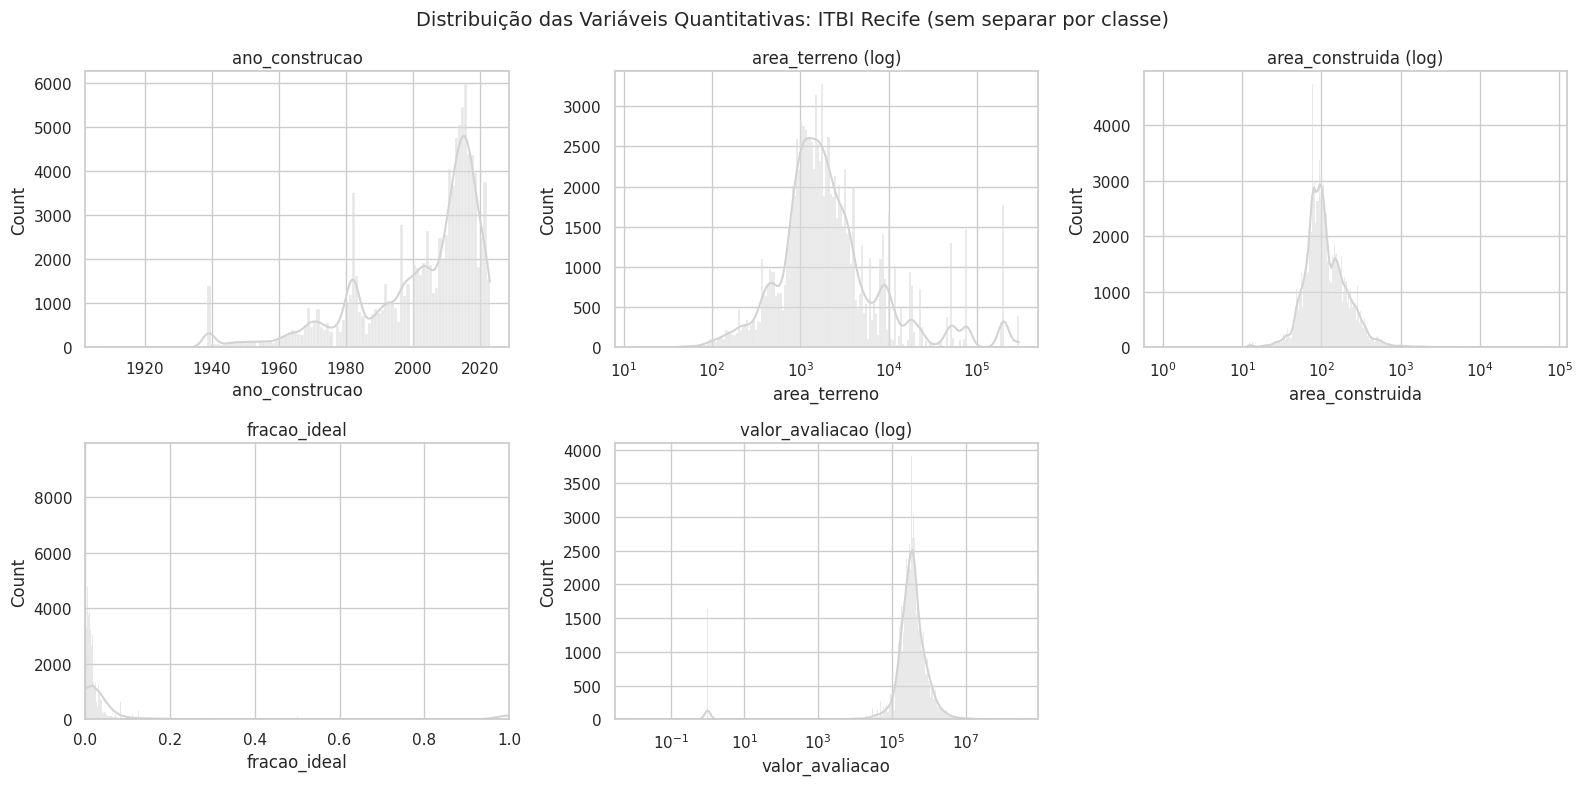

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    usar_log = col in VARS_LOG
    dados = df.loc[df[col] > 0, col] if usar_log else df[col]
    sns.histplot(data=dados, kde=True, color=COR_NEUTRA, ax=axes[i], log_scale=usar_log)
    if col == "fracao_ideal":
        axes[i].set_xlim(0, df[col].quantile(0.99))
    axes[i].set_title(col + (" (log)" if usar_log else ""))

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas: ITBI Recife (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

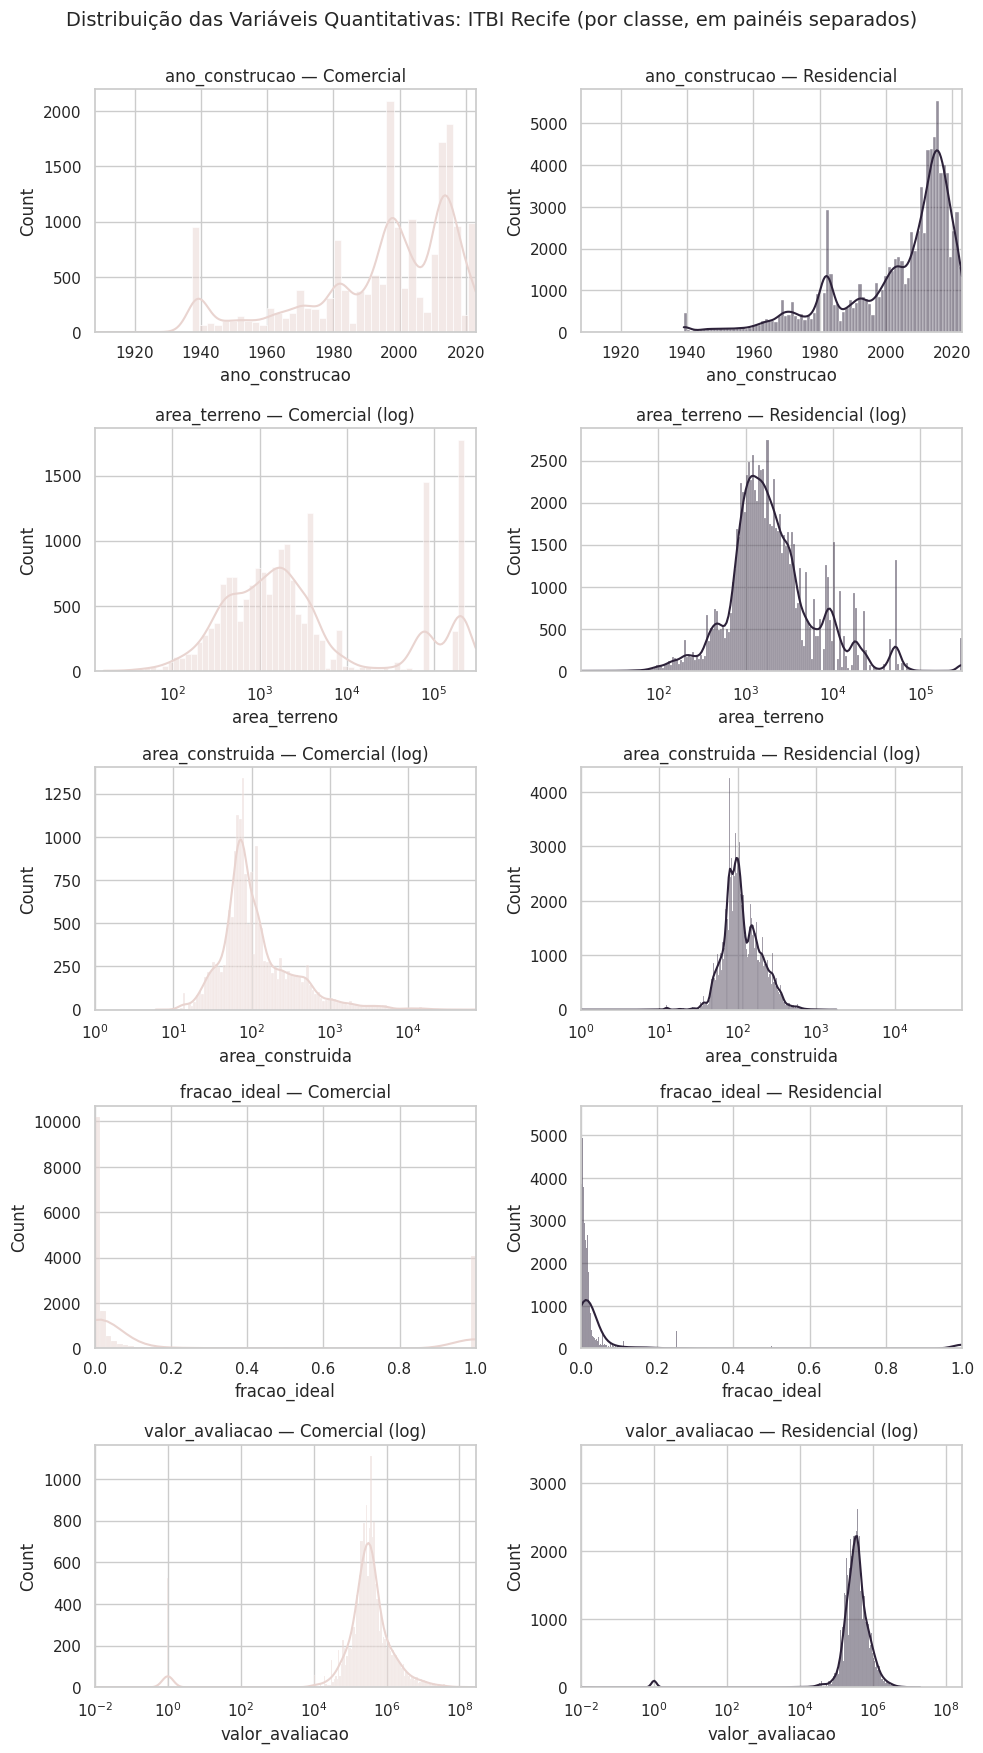

In [18]:
fig, axes = plt.subplots(len(VARS_QUANT), 2, figsize=(10, 3.5 * len(VARS_QUANT)))

for i, col in enumerate(VARS_QUANT):
    usar_log = col in VARS_LOG
    if usar_log:
        lim = (df.loc[df[col] > 0, col].min(), df[col].max())
    elif col == "fracao_ideal":
        lim = (0, df[col].quantile(0.99))
    else:
        lim = (df[col].min(), df[col].max())

    for j, (classe, cor) in enumerate([("Comercial", COR_CONTEXTO), ("Residencial", COR_DESTAQUE)]):
        subset = df[df["tipo_ocupa_bin"] == classe]
        dados = subset.loc[subset[col] > 0, col] if usar_log else subset[col]
        sns.histplot(dados, kde=True, color=cor, ax=axes[i, j], log_scale=usar_log)
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}" + (" (log)" if usar_log else ""))

fig.suptitle("Distribuição das Variáveis Quantitativas: ITBI Recife (por classe, em painéis separados)", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** agora que as classes estão em painéis separados (mesma escala de eixo X em cada linha), fica mais fácil ver: alguma variável parece ter formato bem diferente entre "Normal" e "Cardíaco"?

*Resposta*: `ano_construcao` é a que mostra o formato mais diferente entre as duas classes — Comercial tem uma distribuição bem mais espalhada e deslocada para construções mais antigas, enquanto Residencial se concentra fortemente depois de 2000 (confirmado mais à frente, Seção 6: só ~73% dos imóveis anteriores a 1980 são Residencial, contra quase 88% dos posteriores a 2010).

#### Testes de Aderência

*Será se o colesterol segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste de aderência mais usado pra normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `chol`.

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 108804.
  res = hypotest_fun_out(*samples, **kwds)


Shapiro-Wilk — valor_avaliacao: estatística=0.0928, p-valor=1.817e-183
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


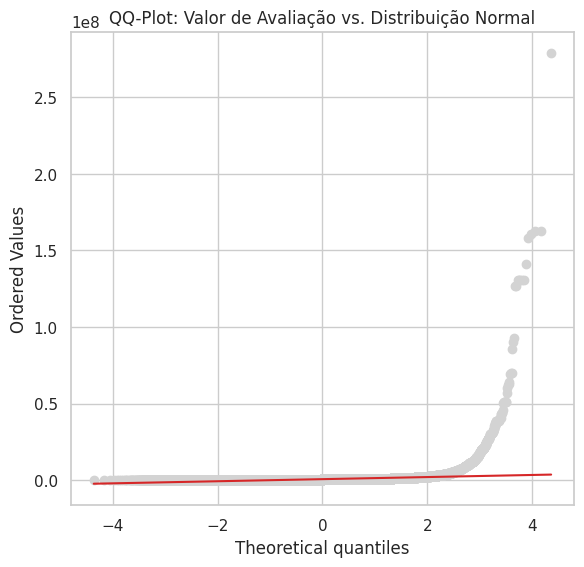

In [19]:
stat_sw, p_valor_sw = stats.shapiro(df["valor_avaliacao"].dropna())
print(f"Shapiro-Wilk — valor_avaliacao: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

# QQ-Plot — valor de avaliação

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["valor_avaliacao"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Valor de Avaliação vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos (roxo) seguissem a reta vermelha de perto, a variável seguiria uma normal. Pontos que se afastam da reta nas pontas indicam cauda mais pesada ou mais leve que a normal — coerente com o resultado do Shapiro-Wilk acima.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. Com n≈303 (nem pequeno, nem enorme) e três evidências concordando — skewness alto, QQ-Plot afastado da reta, e Shapiro-Wilk rejeitando — o resultado é razoavelmente confiável, não um artefato do tamanho da amostra.
- **Como afirmar o resultado:** quando o teste **rejeita** H0 (nosso caso, p < 0.05), a afirmação correta é "temos evidência estatística **contra** a normalidade" que é uma conclusão forte. A frase "não podemos garantir normalidade" cabe no caso oposto: quando o teste **não rejeita** H0, já que a ausência de rejeição nunca prova que os dados são normais, só que não há evidência suficiente contra.

In [20]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
ano_construcao,0.8603,0.0,True
area_terreno,0.2705,0.0,True
area_construida,0.0661,0.0,True
fracao_ideal,0.3946,0.0,True
valor_avaliacao,0.0928,0.0,True


**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Vamos ilustrar com uma única variável (`chol`, colesterol), só pra fixar como essa visualização se lê.

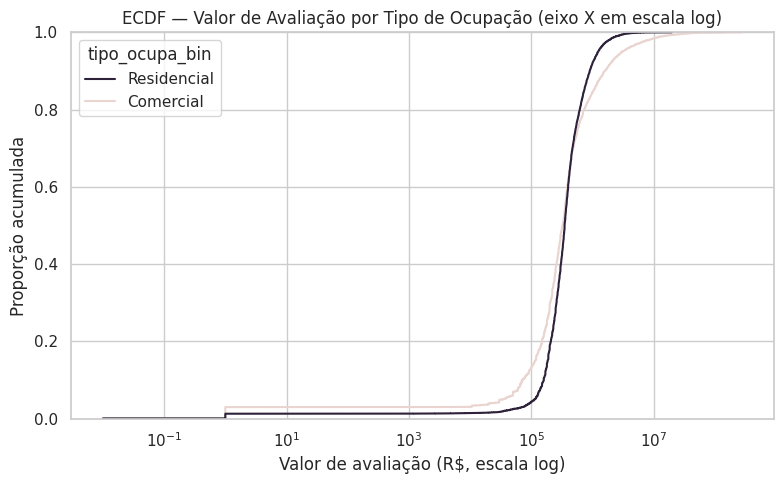

In [21]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df[df["valor_avaliacao"] > 0], x="valor_avaliacao", hue="tipo_ocupa_bin",
             palette={"Comercial": COR_CONTEXTO, "Residencial": COR_DESTAQUE}, log_scale=True)
plt.title("ECDF — Valor de Avaliação por Tipo de Ocupação (eixo X em escala log)")
plt.xlabel("Valor de avaliação (R$, escala log)")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva diz "que fração dos pacientes desse grupo tem colesterol até aqui". Onde as duas curvas (rosa e roxa) se distanciam mais, ali está a faixa de colesterol onde os dois grupos mais diferem, sem precisar decidir uma largura de bin como no histograma.

### Métricas de Tendêncial Central

In [ ]:
media_valor = df["valor_avaliacao"].mean()
mediana_valor = df["valor_avaliacao"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df[df["valor_avaliacao"] > 0], x="valor_avaliacao", kde=True, color=COR_NEUTRA, log_scale=True)
plt.axvline(media_valor, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_valor:.1f}")
plt.axvline(mediana_valor, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_valor:.1f}")
plt.title("Valor de Avaliação: Distribuição com Média e Mediana (eixo X em escala log)")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

# Boxplot e violin plot por classe

palette_classe = {"Comercial": COR_CONTEXTO, "Residencial": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 9), sharex="col")

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, x="tipo_ocupa_bin", y=col, hue="tipo_ocupa_bin",
                palette=palette_classe, legend=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    sns.violinplot(data=df, x="tipo_ocupa_bin", y=col, hue="tipo_ocupa_bin",
                    palette=palette_classe, legend=False, ax=axes[1, i])
    axes[1, i].set_xlabel("")

    if col in VARS_LOG:
        axes[0, i].set_yscale("log")
        axes[1, i].set_yscale("log")

axes[0, 0].set_ylabel("Boxplot")
axes[1, 0].set_ylabel("Violin plot")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot (escala log em área/valor)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre "Normal" e "Cardíaco"? Isso já é um indício — antes mesmo da análise bivariada formal — de que essa variável pode ajudar a diferenciar as duas classes.

*Resposta*: `ano_construcao` de novo se destaca como a variável com a caixa mais deslocada entre as duas classes — indício visual que se confirma depois (Seção 6): é uma das variáveis com diferença mais consistente entre Comercial e Residencial nos testes formais.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

### Visualizando os Outliers

In [ ]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Olhando os outliers encontrados (principalmente em `chol` e `oldpeak`): eles parecem fisiologicamente plausíveis (pacientes reais podem ter colesterol muito alto), ou parecem violar algum limite físico conhecido? Isso muda qual das três categorias se aplica — e, consequentemente, se devemos manter, transformar ou remover.

*Resposta*: A maioria dos outliers de `area_terreno`, `area_construida` e `valor_avaliacao` parece fisiologicamente plausível pro domínio — existem mesmo imóveis comerciais enormes (galpões, hospitais, prédios inteiros) com área e valor muito acima do típico, sem violar nenhuma regra física. Já dois casos específicos são diferentes: `valor_avaliacao == 0` (1 linha — logicamente impossível para uma transação sujeita a imposto) é **erro de dado**, e `fracao_ideal > 1` (9 linhas — a fração ideal de propriedade não pode superar 100%) é **outlier de domínio**. Esses dois são tratados/removidos na próxima seção; os demais (estatísticos) são mantidos.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o que já discutimos: o mecanismo mais provável para `ca`/`thal` é MAR ou MCAR (não MNAR), e o volume é pequeno (poucas linhas em ~300). Com essas duas informações juntas, a decisão pragmática é remover as linhas afetadas — o risco de viés é baixo (mecanismo provavelmente não depende do próprio valor ausente) e o custo de perder ~2% das linhas é pequeno.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df = df[(df["valor_avaliacao"] > 0) & (df["fracao_ideal"] <= 1)].reset_index(drop=True)
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

### Decidindo o Tratamento dos Outliers

Diferente dos ausentes, aqui **não vamos remover automaticamente**. Pelos valores encontrados (dentro de faixas clinicamente plausíveis, ainda que raras), a classificação mais provável é **"Estatístico"**, outliers legítimos, não erros de coleta. Sendo assim, o tratamento recomendado nesse caso é **manter** (a informação é real e pode ser clinicamente relevante — por exemplo, exatamente os pacientes com colesterol mais extremo podem ser os de maior risco) ou, se for necessário para alguma técnica estatística específica mais à frente (ex: métodos sensíveis à assimetria), **transformar**.

Vamos manter os valores originais por enquanto, mas ilustrar como ficaria uma transformação logarítmica em `chol` — útil caso, mais adiante em análises futuras, a assimetria atrapalhe algum teste ou modelo.

In [ ]:
df["valor_avaliacao_log"] = np.log1p(df["valor_avaliacao"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="valor_avaliacao", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"valor_avaliacao original (skew={df['valor_avaliacao'].skew():.2f})")

sns.histplot(data=df, x="valor_avaliacao_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + valor_avaliacao) (skew={df['valor_avaliacao_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria? Mantivemos `chol_log` só como demonstração, mas não vamos usá-la nas próximas seções. A ideia foi mostrar como opção se fosse o objetivo de, por exemplo, alimentar um teste paramétrico que exige normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

*Resposta*: A transformação log reduziu a assimetria em magnitude de forma dramática (de 52,28 para -5,18), mas não deixou a distribuição simétrica — o log1p trocou um skew positivo extremo por um skew negativo ainda considerável. Isso acontece por causa de um pequeno grupo de transações com valor muito próximo de R$ 1 (provavelmente transferências simbólicas/doações entre familiares), que em escala log produzem uma cauda esquerda longa. É um lembrete útil: o log resolve bem a cauda direita comum em dados de valor/área, mas pode criar um problema simétrico quando também existem valores anormalmente baixos perto de zero.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

**Pra discutir:** os valores mudaram muito? Fazia sentido esperar uma diferença grande, considerando que removemos só ~2% das linhas e decidimos **não** alterar nenhum outlier? Esse resultado (pouca mudança) é, na verdade, uma confirmação de que o tratamento foi conservador — não um sinal de que ele não fez nada de útil.

*Resposta*: Não, a mudança foi mínima em todas as 5 variáveis (delta de skewness entre -0,000 e -0,007; delta de curtose entre -0,004 e -0,362) — coerente com o esperado, já que removemos apenas 10 linhas de 108.804 (0,009%) e decidimos manter todos os outliers estatísticos.

**O colesterol ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["valor_avaliacao"].dropna())
print(f"Shapiro-Wilk (antes)  — valor_avaliacao: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — valor_avaliacao: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

**Visualizando antes x depois, lado a lado**

Vamos sobrepor as distribuições de duas variáveis que mais chamaram atenção na Seção 4 (`chol` e `oldpeak`), comparando a versão original (`df_antes`) com a tratada (`df`).

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["valor_avaliacao", "area_construida"]):
    sns.kdeplot(df_antes.loc[df_antes[col] > 0, col], color=COR_CONTEXTO, fill=True, label="Antes", ax=ax, log_scale=True)
    sns.kdeplot(df.loc[df[col] > 0, col], color=COR_DESTAQUE, fill=True, label="Depois", ax=ax, log_scale=True)
    ax.set_title(col + " (log)")
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso é o esperado aqui, já que removemos poucas linhas e não tocamos nos outliers.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

*Resposta*: Sim, as curvas praticamente se sobrepõem — esperado pelo mesmo motivo da resposta anterior: removemos 10 linhas de quase 109 mil, um volume pequeno demais pra mover visivelmente uma curva de densidade.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

#### Visualizando as frequências

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=0)

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

*Resposta*: `estado_conservacao` é de longe a mais desbalanceada — razão de desbalanceamento de 650x e entropia normalizada de apenas 0,071 (quase 0), porque 98,6% dos imóveis são classificados como "Bom". `tipo_imovel` também é bem desbalanceada (razão ~21 mil, dominada por "Apartamento"). Isso significa que qualquer cruzamento com `estado_conservacao` vai ter uma célula dominante e as outras quase vazias — os testes ainda rodam, mas a informação prática que essa variável carrega é limitada.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

Vamos aplicar as duas em todas as qualitativas, incluindo o próprio alvo `doenca_cardiaca`.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["tipo_ocupa_bin"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `doenca_cardiaca` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

*Resposta*: `estado_conservacao` está bem próxima de 0 (0,071), como visto acima. Já o nosso alvo `tipo_ocupa_bin` tem entropia 0,648 — desbalanceado (~5 imóveis Residenciais pra cada 1 Comercial), mais desbalanceado que o `doenca_cardiaca` da demonstração (quase 1:1), mas ainda longe de 0, então segue utilizável nos testes da próxima seção, com essa assimetria em mente.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

*Resposta*: Sim, e de forma marcante: `area_terreno` x `fracao_ideal` tem Pearson de apenas -0,101 mas Spearman de -0,825 — uma diferença enorme. É sinal de uma relação monotônica forte, mas não linear, que o Spearman captura e o Pearson praticamente não vê — esperado, já que `fracao_ideal` é definida a partir de uma razão (área da unidade sobre área total do empreendimento), não de uma relação em linha reta com `area_terreno`.

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `age` x `thalach` por um motivo de domínio, não só estatístico: existe uma relação fisiológica entre idade e frequência cardíaca máxima, o que torna esse par um bom candidato pra visualizar uma tendência real.

**Nota para quando vocês replicarem no dataset de vocês:** nem sempre vai existir uma relação de domínio óbvia e, nesse caso, uma alternativa é escolher o par com o maior |correlação| na tabela acima, deixando a própria estatística guiar a escolha.

In [ ]:
dados_scatter = df[(df["area_construida"] > 0) & (df["valor_avaliacao"] > 0)]

plt.figure(figsize=(7, 5))
sns.scatterplot(data=dados_scatter, x="area_construida", y="valor_avaliacao", hue="tipo_ocupa_bin",
                palette={"Comercial": COR_CONTEXTO, "Residencial": COR_DESTAQUE}, alpha=0.5, s=15)
plt.xscale("log")
plt.yscale("log")
plt.title("Área Construída x Valor de Avaliação (escala log-log)")
plt.xlabel("Área construída (m², escala log)")
plt.ylabel("Valor de avaliação (R$, escala log)")
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível (conforme a idade aumenta, `thalach` tende a cair)? As duas classes ocupam regiões diferentes do gráfico, ou estão misturadas?

*Resposta*: Sim, existe uma tendência crescente clara (quanto maior a área construída, maior o valor — Spearman = 0,781 entre as duas), mas com dispersão grande: dois imóveis de área parecida podem ter valores bem diferentes. As duas classes (Comercial e Residencial) aparecem bastante misturadas nessa relação, sem uma fronteira visual nítida entre elas.

#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 (tabela generalizada do Shapiro-Wilk) que **nenhuma** das nossas quantitativas passou nesse teste. Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test, e **Kruskal-Wallis** no lugar da ANOVA. Vamos calcular os dois lado a lado pra comparar, mas o resultado não-paramétrico é o que deveríamos reportar como principal.

In [ ]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_comercial = df.loc[df["tipo_ocupa_bin"] == "Comercial", col]
    grupo_residencial = df.loc[df["tipo_ocupa_bin"] == "Residencial", col]

    stat_t, p_t = stats.ttest_ind(grupo_comercial, grupo_residencial, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_comercial, grupo_residencial)                 # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")

**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar, é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico. Reportar apenas o T-Test, sem essa ressalva, seria estatisticamente inconsistente com o que a própria Seção 3 já mostrou sobre a normalidade dessas variáveis.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`cp` (tipo de dor no peito) tem 4 categorias. Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico, equivalente pra 3+ grupos) lado a lado.

*Resposta*: Não totalmente — `area_terreno` diverge: o T-Test dá p≈0 (sugerindo diferença entre Comercial e Residencial), mas o Mann-Whitney dá p=0,65 (sem evidência de diferença). É exatamente o caso em que a ressalva abaixo importa: como nenhuma variável passou no Shapiro-Wilk (Seção 3), o Mann-Whitney é o resultado que deveríamos priorizar — e aqui ele muda a conclusão prática. As outras 4 variáveis concordam entre os dois testes.

In [ ]:
grupos_padrao = [grupo["area_construida"].values for _, grupo in df.groupby("padrao_acabamento")]

stat_anova, p_anova = stats.f_oneway(*grupos_padrao)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_padrao)          # não-paramétrico

print(f"ANOVA          — area_construida entre categorias de padrao_acabamento: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — area_construida entre categorias de padrao_acabamento: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="padrao_acabamento", y="area_construida", color=COR_NEUTRA, order=["Simples", "Médio", "Superior"], showfliers=False)
plt.yscale("log")
plt.title("Área Construída por Padrão de Acabamento (escala log)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `cp`? Como já sabemos que `thalach` não é normal, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal, a ANOVA fica só como contraste.

*Resposta*: Sim, os dois concordam que existe diferença entre pelo menos uma categoria de `padrao_acabamento` (ANOVA p≈3,6×10⁻⁵; Kruskal-Wallis p≈0) — ambos rejeitam a hipótese de igualdade entre grupos. Como `area_construida` não é normal (Seção 3), o Kruskal-Wallis é o resultado que reportamos como principal; a ANOVA fica só como contraste.

#### Quantitativa x Qualitativa

In [ ]:
contingencia_estado = pd.crosstab(df["estado_conservacao"], df["tipo_ocupa_bin"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_estado)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_estado, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"estado_conservacao x tipo_ocupa_bin (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()

**Pra discutir:** o p-valor do Qui-Quadrado indica que `thal` e `doenca_cardiaca` são independentes, ou há associação estatisticamente significativa entre elas?

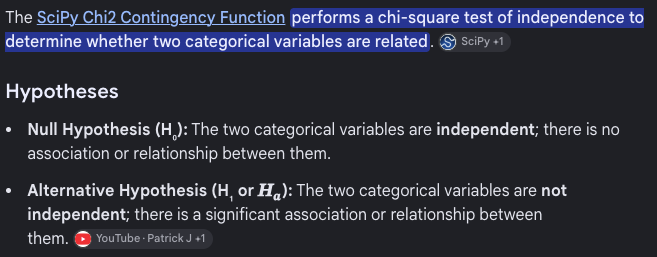

*Resposta*: O p-valor (≈1,8×10⁻⁸²) indica associação estatisticamente significativa entre `estado_conservacao` e `tipo_ocupa_bin` — a hipótese de independência é rejeitada com folga. Vale a mesma ressalva de sempre com N grande: `estado_conservacao` está extremamente concentrada em "Bom" (98,6% da base), então boa parte dessa associação vem de proporções ligeiramente diferentes dentro dessa única categoria dominante, não de uma diferença dramática entre os grupos.

#### Avaliação de Fairness

Olhar o desbalanceamento da base inteira é só metade da história. Uma pergunta recorrente em discussões de **fairness** (justiça algorítmica) é: será que a distribuição do desfecho se comporta igual em diferentes subgrupos de atributos sensíveis (sexo e faixa etária, no nosso caso)? Se não, isso pode refletir um padrão real (ex: idade avançada é fator de risco documentado) ou um viés na forma como os dados foram coletados — de qualquer forma, é algo que vale mapear **antes** de qualquer modelagem.

In [ ]:
df["sexo_label"] = df["padrao_acabamento"]
df["faixa_etaria"] = pd.cut(df["ano_construcao"], bins=[0, 1980, 2000, 2010, 2030],
                             labels=["<1980", "1980-1999", "2000-2009", "2010+"])

print("Desbalanceamento — sexo:")
print(metrica_desbalanceamento(df["sexo_label"]))
print("\nDesbalanceamento — faixa etária:")
print(metrica_desbalanceamento(df["faixa_etaria"]))

In [ ]:
prop_por_sexo = pd.crosstab(df["sexo_label"], df["tipo_ocupa_bin"], normalize="index").round(3)
prop_por_faixa = pd.crosstab(df["faixa_etaria"], df["tipo_ocupa_bin"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

prop_por_sexo["Residencial"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Residencial' por Sexo")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

prop_por_faixa["Residencial"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Residencial' por Faixa Etária")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

**Pra discutir:** a proporção de diagnóstico positivo varia bastante entre sexo ou faixa etária? Isso pode refletir um padrão clínico real e bem documentado (ex: risco cardíaco cresce com a idade), ou pode ser um artefato de **quem** foi encaminhado para o exame nesses hospitais específicos? A pergunta "a distribuição do desfecho é uniforme entre grupos protegidos?" é o ponto de partida de várias discussões de fairness em ciência de dados, e não tem uma resposta única: depende do contexto e da causa por trás da disparidade.

*Resposta*: Por "sexo" (aqui, padrão de acabamento): a variação é modesta — a proporção Residencial vai de 78,1% (Simples) a 85,2% (Médio), poucos pontos percentuais de diferença. Já por "faixa etária" (aqui, época de construção): a variação é bem mais forte — de 73% Residencial em construções anteriores a 1980 pra quase 88% depois de 2010, uma tendência clara e crescente. Isso é coerente com um padrão real do mercado imobiliário recente (o boom de apartamentos residenciais em Recife nas últimas duas décadas), não necessariamente um viés de coleta — mas, como no exemplo original, um teste estatístico sozinho não distingue as duas explicações.

In [ ]:
for atributo in ["sexo_label", "faixa_etaria"]:
    contingencia = pd.crosstab(df[atributo], df["tipo_ocupa_bin"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x tipo_ocupa_bin (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre sexo/faixa etária e o desfecho? Lembrando que mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um fator de risco real (idade), pode ser um viés de quem foi encaminhado ao exame (possivelmente sexo), ou uma mistura das duas coisas. Um teste estatístico aponta *que* existe associação, não *a causa* dela — essa distinção é o núcleo de qualquer discussão séria de fairness.

*Resposta*: Sim, os dois cruzamentos dão p-valor praticamente zero — confirmando associação estatisticamente significativa tanto entre padrão de acabamento quanto entre época de construção e o tipo de ocupação. Mas associação não é causa: a época de construção provavelmente reflete uma mudança real do mercado (mais empreendimentos residenciais recentes), não um viés de "quem foi encaminhado" a registrar a transação — a analogia com fairness clínica é imperfeita aqui justamente porque não existe um agente de triagem envolvido, só a dinâmica do próprio mercado.

#### Outliers bivariados

In [ ]:
dados_joint = df.loc[(df["area_terreno"] > 0) & (df["area_construida"] > 0),
                     ["area_terreno", "area_construida", "tipo_ocupa_bin"]].copy()
dados_joint["area_terreno"] = np.log10(dados_joint["area_terreno"])
dados_joint["area_construida"] = np.log10(dados_joint["area_construida"])

g = sns.jointplot(data=dados_joint, x="area_terreno", y="area_construida", hue="tipo_ocupa_bin",
                   palette={"Comercial": COR_CONTEXTO, "Residencial": COR_DESTAQUE}, alpha=0.5, height=6)
g.ax_joint.set_xlabel("area_terreno (log10 m²)")
g.ax_joint.set_ylabel("area_construida (log10 m²)")
plt.suptitle("Área do Terreno x Área Construída: outliers conjuntos? (escala log-log)", y=1.02)
plt.show()

**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados (Seção 3/4), mas que se destaca aqui como uma combinação incomum de `trestbps` e `chol`?

*Resposta*: Sim — a correlação entre `area_terreno` e `area_construida` é praticamente nula (Spearman = -0,069), o que já é surpreendente: ao contrário da intuição (terreno maior → mais espaço pra construir), aqui as duas quase não se relacionam. Isso aparece no gráfico como imóveis com terreno grande e área construída pequena (ou vice-versa) — combinações que não se destacavam como outliers nos histogramas univariados de cada variável isoladamente, mas que saltam aos olhos como incomuns quando as duas são vistas juntas (coerente, por exemplo, com estacionamentos ou galpões com baixa taxa de ocupação do terreno).

#### Análise Multivariada

##### Matriz de Correlação

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_QUANT].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

*Resposta*: `area_terreno` x `fracao_ideal` (Spearman = -0,825) é a correlação mais forte da matriz — mas essa é redundância **por construção**: a fração ideal é calculada, em parte, a partir da área do terreno total do empreendimento, então as duas não são informações totalmente independentes (vale não tratá-las como duas variáveis separadas numa modelagem futura). `area_construida` x `valor_avaliacao` (0,781) também é forte, mas é uma relação de mercado genuína (área é o principal determinante físico do valor), não uma redundância de definição.

##### Correlograma

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = np.corrcoef(x, y)[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

# amostra de 3.000 linhas (108 mil pontos deixariam o PairGrid pesado demais) e,
# nas 3 variáveis de cauda pesada, plotamos log(1+x) só para desenhar o gráfico —
# os valores originais continuam intactos em `df`.
amostra_correlograma = df[VARS_QUANT].sample(3000, random_state=42).copy()
for col in VARS_LOG:
    amostra_correlograma[col] = np.log1p(amostra_correlograma[col])
amostra_correlograma = amostra_correlograma.rename(columns={col: f"{col} (log)" for col in VARS_LOG})

g = sns.PairGrid(amostra_correlograma, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

# barra de cor única, compartilhada (cada subplot superior tem seu próprio scatter)
sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão × Correlação", y=1.02, fontsize=15)

---
> 🆕 **NOVA SEÇÃO (não estava no notebook da aula)** — as 4 células abaixo (esta, mais 3) servem apenas para salvar os datasets em disco.

## 🆕 Download dos Datasets

Vamos salvar duas versões do dataset com nomes próprios, para não sobrescrever os arquivos de exemplo do professor (`data/raw/dataset.csv` / `data/clean/dataset.csv`, do Heart Disease):

- `data/raw/meu_dataset.csv`: o dataset **original**, como veio do ITBI (concatenação bruta dos 9 CSVs anuais de `data/raw/archive.zip`, sem filtro de linhas e sem as colunas derivadas `tipo_ocupa_bin`, `valor_avaliacao_log`, `sexo_label` e `faixa_etaria`).
- `data/clean/meu_dataset.csv`: o dataset **tratado**, no estado final do `df` ao longo da EDA (linhas com `valor_avaliacao` inválido ou `fracao_ideal` > 1 removidas, e colunas derivadas criadas).

> Rode o notebook **do início ao fim** antes desta seção, para que o `df` esteja no estado final.
>
> **Nota:** para o `app.py` ler `meu_dataset.csv`, ajuste o caminho padrão em `src/data_loader.py`.

In [ ]:
# 🆕 NOVA CÉLULA — define as pastas de destino (funciona rodando de notebooks/ ou da raiz do projeto)
from pathlib import Path

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)

In [ ]:
# 🆕 NOVA CÉLULA — dataset ORIGINAL (reconstruído a partir dos CSVs brutos do ITBI, igual à célula de carregamento)
df_raw = pd.concat(
    [pd.read_csv(a, sep=";", decimal=",", encoding="utf-8") for a in arquivos],
    ignore_index=True,
)
df_raw["valor_avaliacao"] = df_raw["valor_avaliacao"].astype(float)
df_raw["data_transacao"] = pd.to_datetime(df_raw["data_transacao"])
df_raw.to_csv(PASTA_RAW / "meu_dataset.csv", index=False)

print(f"Raw salvo em {PASTA_RAW / 'meu_dataset.csv'} — {df_raw.shape[0]} linhas x {df_raw.shape[1]} colunas")

In [ ]:
# 🆕 NOVA CÉLULA — dataset TRATADO (estado final do `df`)
df.to_csv(PASTA_CLEAN / "meu_dataset.csv", index=False)

print(f"Clean salvo em {PASTA_CLEAN / 'meu_dataset.csv'} — {df.shape[0]} linhas x {df.shape[1]} colunas")
print(f"Linhas removidas no tratamento: {df_raw.shape[0] - df.shape[0]}")

## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.




## Síntese

### Principais conclusões

1. A base de ITBI de Recife (2015-2023, ~108 mil transações) não tem duplicadas e não tem ausentes nas 5 variáveis quantitativas usadas na análise — os únicos ausentes reais (`complemento`, `sfh`) ficam fora desse conjunto e têm volume pequeno.
2. Nenhuma variável quantitativa passa no Shapiro-Wilk — `valor_avaliacao`, `area_terreno` e `area_construida` têm a assimetria mais extrema (puxada por uma cauda real de imóveis excepcionais: hospitais, galpões, prédios comerciais inteiros), a ponto de precisarem de escala log só pra serem visualizadas de forma legível. A mediana (não a média) e os testes não-paramétricos (Mann-Whitney, Kruskal-Wallis, Spearman) são a escolha correta em toda a análise.
3. Encontramos outliers de dois tipos bem diferentes: `valor_avaliacao == 0` (1 linha, impossível para uma transação sujeita a imposto — erro de dado) e `fracao_ideal > 1` (9 linhas, viola a própria definição da variável — outlier de domínio). Ambos foram removidos; os demais outliers (área/valor extremos) são estatisticamente plausíveis e foram mantidos.
4. Com N ≈ 109 mil, o p-valor sozinho não é suficiente: `area_terreno` teve p≈0 no T-Test mas p=0,65 no Mann-Whitney (o teste correto, dado que nenhuma variável é normal) — ou seja, o teste "errado" teria sugerido uma diferença entre Comercial e Residencial que na verdade não existe.
5. `ano_construcao` é a variável com relação mais clara com o restante da análise (diferencia melhor Residencial de Comercial, tanto visualmente quanto nos testes); já `area_terreno` e `area_construida`, apesar da intuição, quase não se correlacionam entre si (Spearman ≈ -0,07) — terreno grande não implica construção grande neste mercado.

### Declaração de Uso de IA

- **Ferramenta utilizada:** Claude Code (Anthropic).
- **Para o que foi aplicada:** leitura e perfilamento do dataset (estrutura, tipos, nulos, valores fora de faixa), cálculo das estatísticas reais usadas nas respostas, e redação das respostas de discussão a partir desses números.
- **O que foi aceito, modificado ou rejeitado, e por quê:** só os campos de resposta foram preenchidos. A primeira versão dos gráficos usava escala linear (igual ao notebook de referência) e isso escondia 99% da distribuição de `area_terreno`/`area_construida`/`valor_avaliacao` atrás de um punhado de imóveis excepcionais — corrigido trocando essas 3 variáveis para escala log nos gráficos (sem alterar nenhum dado ou estatística). A ideia de criar uma classe binária artificial via mediana de `valor_avaliacao` foi rejeitada por gerar comparação circular; usei `tipo_ocupa` (Residencial x Comercial), variável categórica já existente no dado bruto.